# Notebook 01: Data Exploration
Swahili concern classification | Obonyo Paul Rapando (169688)

**Inputs** (Google Drive, `data/annotated/`): `labelled_concerns.csv`, optional `resident_test.csv`
**Outputs** (`results/eda/`): figures and `eda_summary.json`

This notebook explores and checks the dataset. It does not build or change it. The dataset is built locally by `scripts/build_dataset.py`.

In [4]:
from google.colab import drive
import os
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/PaulObonyo_169688'
ANN_DIR = os.path.join(PROJECT, 'data', 'annotated')
EDA_DIR = os.path.join(PROJECT, 'results', 'eda')
os.makedirs(EDA_DIR, exist_ok=True)

SEED = 42

Mounted at /content/drive


## 1. Load and validate

In [5]:
df = pd.read_csv(os.path.join(ANN_DIR, 'labelled_concerns.csv'))

assert {'sentence', 'label', 'source'}.issubset(df.columns)
assert df['sentence'].notna().all() and df['label'].notna().all()

CLASSES = sorted(df['label'].unique())
print(f'{len(df):,} rows, {len(CLASSES)} classes: {CLASSES}')
print(df['label'].value_counts())

6,000 rows, 3 classes: ['Education', 'Food Security', 'Health']
label
Education        2000
Food Security    2000
Health           2000
Name: count, dtype: int64


## 2. Sample inspection
Read these and confirm each sentence fits its category definition in `docs/annotation_codebook.md`. Note the percentage that do not fit; it goes in your Chapter 5 documentation.

In [6]:
for label in CLASSES:
    print(f'\n--- {label} ---')
    subset = df[df['label'] == label]
    sample = subset.sample(min(8, len(subset)), random_state=SEED)
    for _, row in sample.iterrows():
        print(f"[{row['source']}] {row['sentence']}")


--- Education ---
[ELIMU_Cleaned.txt] kwafungo ni jina la kata ya wilaya ya muheza katika mkoa wa tanga tanzania
[ELIMU_Cleaned.txt] hizi ni pamoja na homa kang ata upele aumaambukizi
[ELIMU_Cleaned.txt] wadudu na baadhi ya moluska hutumia ugiligili unaoitwa hemolimfu badala ya damu tofauti ikiwa kwamba hemolimfu haipatikani katika mfumo wa usambazaji uliofungwa
[ELIMU_Cleaned.txt] bidhaa hii inaweza kuwa sokoni katika muda wa miaka mitatu ijayo
[ELIMU_Cleaned.txt] ghuba ya bengali ni hori kubwa ya bahari hindi kati ya bara hindi rasi ya malay na sri lanka yenye umbo la pembetatu
[ELIMU_Cleaned.txt] katika nchi za kaskazini ilikuwa njia ya pekee ya kutia utamu kwenye chakula kabla ya kupatikana kwa sukari kwa njia ya biashara ya kimataifa
[ELIMU_Cleaned.txt] baadaye hong kong na macau zikarudi mikononi mwa serikali ya china lakini kuna kipindi hujifikiria kuwa wao kama sio wamoja wa sehemu ya uchina bara
[ELIMU_Cleaned.txt] yeye imeweza kuwafikia kwenye mteremko wa kusini magharibi

-

## 3. Data quality

In [7]:
df['chars'] = df['sentence'].str.len()
df['words'] = df['sentence'].str.split().str.len()

labels_per_sentence = df.groupby('sentence')['label'].nunique()
quality = {
    'rows': int(len(df)),
    'empty_sentences': int((df['sentence'].str.strip() == '').sum()),
    'duplicate_rows': int(df.duplicated(subset=['sentence', 'label']).sum()),
    'conflicting_labels': int((labels_per_sentence > 1).sum()),
    'numeric_only': int(df['sentence'].str.fullmatch(r'\d+').sum()),
}
print(pd.Series(quality))
print(df.groupby('label')[['chars', 'words']].agg(['mean', 'median', 'min', 'max']).round(1))

rows                  6000
empty_sentences          0
duplicate_rows           0
conflicting_labels       0
numeric_only             0
dtype: int64
               chars                 words               
                mean median min  max  mean median min max
label                                                    
Education      111.5   99.5  13  299  17.8   16.0   2  51
Food Security  120.8  112.0  10  300  18.9   18.0   1  52
Health         121.5  115.0  11  300  19.0   18.0   1  56


## 4. Text format check
If the corpus is lowercase without punctuation while Whisper output has capitals and punctuation, the classifier sees two text styles. In that case, apply the same normalisation in training and in the backend.

In [8]:
df['has_upper'] = df['sentence'].str.contains(r'[A-Z]')
df['has_punct'] = df['sentence'].str.contains(r'[^\w\s]')

format_check = df.groupby('label')[['has_upper', 'has_punct']].mean().round(3)
print('Share of sentences containing uppercase letters / punctuation:')
print(format_check)

Share of sentences containing uppercase letters / punctuation:
               has_upper  has_punct
label                              
Education            0.0        0.0
Food Security        0.0        0.0
Health               0.0        0.0


## 5. Class and source distribution

label
Education        2000
Food Security    2000
Health           2000
Name: count, dtype: int64
Imbalance ratio (min/max): 1.00
Classes are reasonably balanced


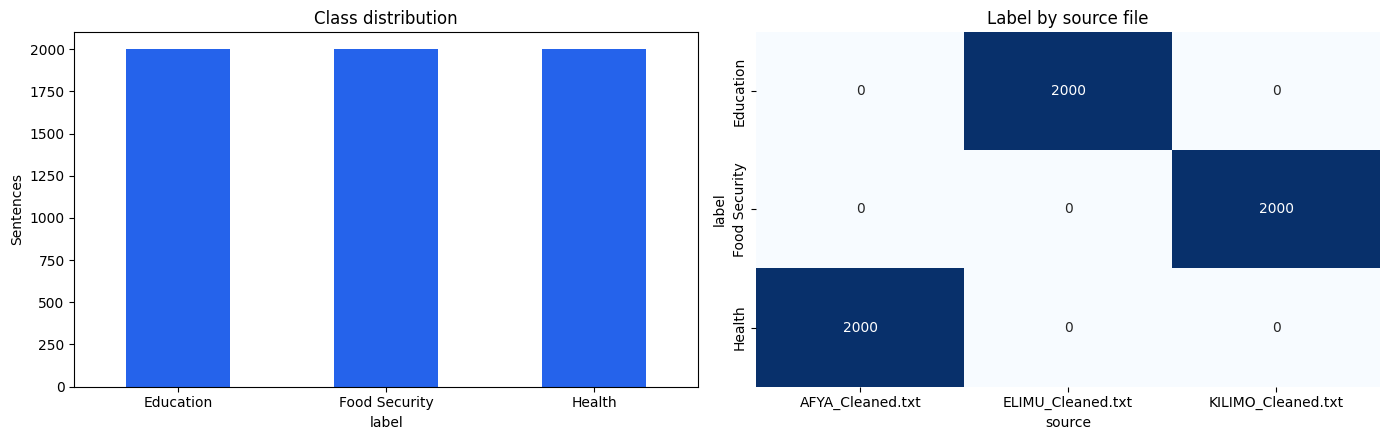

In [9]:
counts = df['label'].value_counts().reindex(CLASSES)
ratio = counts.min() / counts.max()
print(counts)
print(f'Imbalance ratio (min/max): {ratio:.2f}')
print('Classes are reasonably balanced' if ratio >= 0.5
      else 'Imbalance: compare class weights and SMOTE in Notebook 02')

source_table = pd.crosstab(df['label'], df['source'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
counts.plot.bar(ax=axes[0], color='#2563EB')
axes[0].set_title('Class distribution')
axes[0].set_ylabel('Sentences')
axes[0].tick_params(axis='x', rotation=0)
sns.heatmap(source_table, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set_title('Label by source file')
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, 'class_and_source.png'), dpi=150)
plt.show()

## 6. Sentence length
Large length differences between source files can let a model separate classes by style instead of meaning.

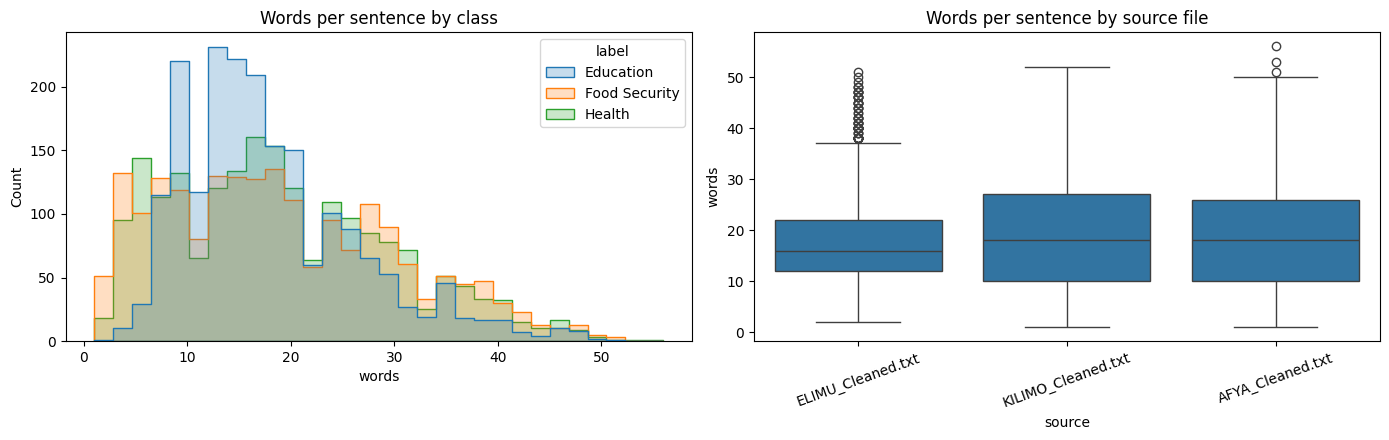

                     count  mean   std  min   25%   50%   75%   max
source                                                             
AFYA_Cleaned.txt    2000.0  19.0  10.6  1.0  10.0  18.0  26.0  56.0
ELIMU_Cleaned.txt   2000.0  17.8   8.4  2.0  12.0  16.0  22.0  51.0
KILIMO_Cleaned.txt  2000.0  18.9  11.2  1.0  10.0  18.0  27.0  52.0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x='words', hue='label', element='step', bins=30, ax=axes[0])
axes[0].set_title('Words per sentence by class')
sns.boxplot(data=df, x='source', y='words', ax=axes[1])
axes[1].set_title('Words per sentence by source file')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, 'sentence_length.png'), dpi=150)
plt.show()

print(df.groupby('source')['words'].describe().round(1))

## 7. Vocabulary

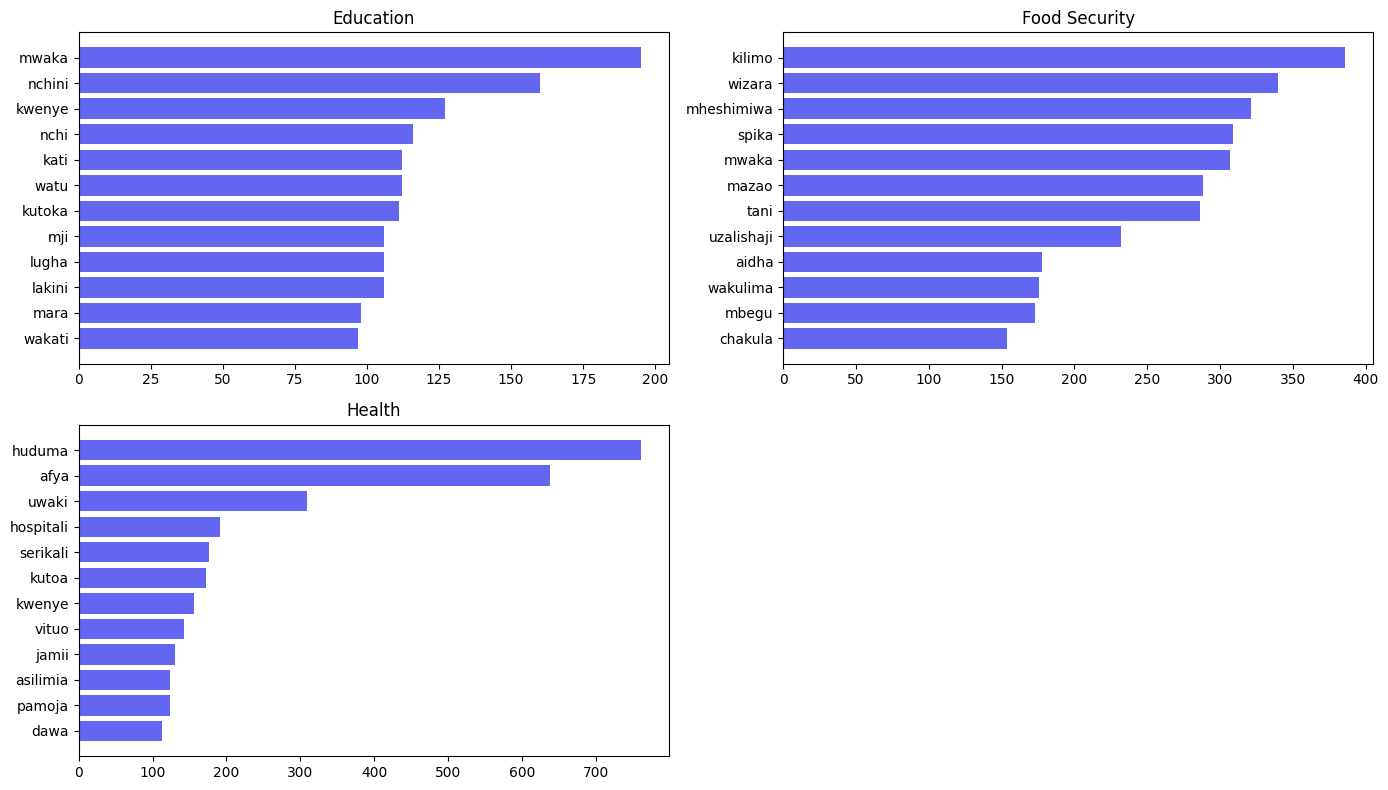

In [11]:
STOPWORDS = {'na', 'ya', 'wa', 'kwa', 'la', 'za', 'ni', 'katika', 'hii', 'hiyo',
             'pia', 'au', 'ile', 'yake', 'wao', 'kuwa', 'kama', 'ama', 'cha',
             'vya', 'huo', 'hili', 'hilo', 'kuna', 'ili', 'sana', 'kila', 'huu'}


def top_words(texts, n=12):
    words = ' '.join(texts).lower().split()
    words = [w for w in words if w.isalpha() and len(w) > 2 and w not in STOPWORDS]
    return Counter(words).most_common(n)


fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, label in zip(axes.flatten(), CLASSES):
    words, freqs = zip(*top_words(df.loc[df['label'] == label, 'sentence']))
    ax.barh(words, freqs, color='#6366F1')
    ax.invert_yaxis()
    ax.set_title(label)
for ax in axes.flatten()[len(CLASSES):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, 'top_words_per_class.png'), dpi=150)
plt.show()

## 8. Resident test set
`resident_test.csv` holds first-person sentences written for evaluation only. It must not appear in training.

In [12]:
test_path = os.path.join(ANN_DIR, 'resident_test.csv')
resident_summary = None

if os.path.exists(test_path):
    rt = pd.read_csv(test_path)
    rt['words'] = rt['sentence'].str.split().str.len()
    print(rt['label'].value_counts())

    unknown = set(rt['label']) - set(CLASSES)
    train_text = set(df['sentence'].str.lower().str.strip())
    overlap = int(rt['sentence'].str.lower().str.strip().isin(train_text).sum())

    print('Labels not in training data:', unknown or 'none')
    print('Sentences also in training data:', overlap)
    print(f"Mean words: resident test {rt['words'].mean():.1f}, corpus {df['words'].mean():.1f}")

    resident_summary = {
        'rows': int(len(rt)),
        'class_counts': {k: int(v) for k, v in rt['label'].value_counts().items()},
        'overlap_with_training': overlap,
        'mean_words': round(float(rt['words'].mean()), 1),
    }
else:
    print('resident_test.csv not found. Create it before Notebook 03.')

label
Food Security    30
Health           30
Education        30
Name: count, dtype: int64
Labels not in training data: none
Sentences also in training data: 0
Mean words: resident test 7.4, corpus 18.6


## 9. AfroXLMR check
Set Runtime > Change runtime type > T4 GPU before running this cell.

In [13]:
import torch
from transformers import AutoTokenizer, AutoModel

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

MODEL_NAME = 'Davlan/afro-xlmr-base'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()


def mean_pool(hidden, mask):
    mask = mask.unsqueeze(-1).float()
    return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


samples = df.groupby('label').head(1)['sentence'].tolist()
inputs = tokenizer(samples, return_tensors='pt', padding=True,
                   truncation=True, max_length=128).to(device)

with torch.no_grad():
    embeddings = mean_pool(model(**inputs).last_hidden_state, inputs['attention_mask'])

print('Embedding shape:', tuple(embeddings.shape))
assert embeddings.shape[1] == 768

Device: cuda Tesla T4


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Embedding shape: (3, 768)


## 10. Save summary

In [14]:
summary = {
    'rows': int(len(df)),
    'classes': CLASSES,
    'class_counts': {k: int(v) for k, v in counts.items()},
    'imbalance_ratio': round(float(ratio), 3),
    'quality': quality,
    'format_check': format_check.to_dict(),
    'sources': sorted(df['source'].unique().tolist()),
    'resident_test': resident_summary,
    'embedding_model': MODEL_NAME,
    'embedding_dim': int(embeddings.shape[1]),
    'device': device,
}

summary_path = os.path.join(EDA_DIR, 'eda_summary.json')
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

print(f'Saved {summary_path}')
print('Next: run Notebook 02.')

Saved /content/drive/MyDrive/PaulObonyo_169688/results/eda/eda_summary.json
Next: run Notebook 02.
